# <span style = 'color:Orange'>**Naive Bayes Classifier**</span>


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [16]:
df = pd.read_csv('drug_class.csv')
df.head()

,Age,Gender,BloodPressure,Cholestrol,Na_to_K,Class
0,23,M,LOW,HIGH,7.301033,drugC
1,69,M,LOW,HIGH,15.478000,drugY
2,74,M,HIGH,HIGH,9.516477,drugB
3,60,M,HIGH,NORMAL,8.742942,drugB
4,39,F,NORMAL,NORMAL,9.715872,drugX


In [17]:
# Categorizing columns for encoding
scaling = ['Age','Na_to_K']
ordinal_bp = ['BloodPressure']
ordinal_chol = ['Cholestrol']
onehot_gender = ['Gender']

feature_Cols = scaling + onehot_gender + ordinal_bp + ordinal_chol

x = df[feature_Cols]
y = df['Class']

# train-test split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [18]:
# Individual pipelines

scale_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])

onehot_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_chol_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(
        categories=[['NORMAL', 'HIGH']]
    ))
])

ordinal_bp_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(
        categories=[['LOW', 'NORMAL', 'HIGH']]
    ))
])

# Full preprocessing pipeline

preprocessor = ColumnTransformer(transformers=[
    ('scaled_pipeline', scale_pipeline, scaling),
    ('onehot_pipeline', onehot_pipeline, onehot_gender),
    ('ordinal_chol_pipeline', ordinal_chol_pipeline, ordinal_chol),
    ('ordinal_bp_pipeline', ordinal_bp_pipeline, ordinal_bp)
])

preprocessor

ColumnTransformer(transformers=[('scaled_pipeline',
                                 Pipeline(steps=[('scale', StandardScaler())]),
                                 ['Age', 'Na_to_K']),
                                ('onehot_pipeline',
                                 Pipeline(steps=[('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender']),
                                ('ordinal_chol_pipeline',
                                 Pipeline(steps=[('encode',
                                                  OrdinalEncoder(categories=[['NORMAL',
                                                                              'HIGH']]))]),
                                 ['Cholestrol']),
                                ('ordinal_bp_pipeline',
                                 Pipeline(steps=[('encode',
                                                  OrdinalEncoder(categories=[['LOW',
                                                                              'NORMAL',
                                                                              'HIGH']]))]),
                                 ['BloodPressure'])])

In [19]:
# model train
model = Pipeline(
    steps = [
        ('preprocess',preprocessor),
        ('classify',GaussianNB())
    ]
)

# hyperparameter tuning
params_grid= {
    'classify__var_smoothing': np.logspace(-12, -6, 7)
}

grid = GridSearchCV(
    estimator=model,
    param_grid=params_grid,
    cv = 5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(x_train, y_train)

print('best model: ',grid.best_estimator_)
print('best parameters: ',grid.best_params_)
print('best score: ',grid.best_score_)

best model:  Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('scaled_pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age', 'Na_to_K']),
                                                 ('onehot_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender']),
                                                 ('ordinal_chol_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['NORMAL',
                                                                            

In [20]:
nb_best = grid.best_estimator_
nb_best

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('scaled_pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age', 'Na_to_K']),
                                                 ('onehot_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender']),
                                                 ('ordinal_chol_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['NORMAL',
                                                                                               'HIGH']]))]),
                                                  ['Cholestrol']),
                                                 ('ordinal_bp_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['LOW',
                                                                                               'NORMAL',
                                                                                               'HIGH']]))]),
                                                  ['BloodPressure'])])),
                ('classify', GaussianNB(var_smoothing=np.float64(1e-07)))])

accuracy_score:  0.945054945054945
recall_score:  0.9583333333333334



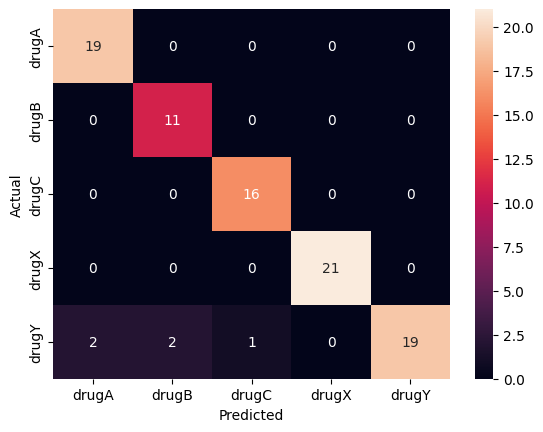

In [21]:
y_Pred = nb_best.predict(x_test)
print('accuracy_score: ',accuracy_score(y_test, y_Pred))
print('recall_score: ',recall_score(y_test, y_Pred,average='macro',zero_division=0))

print()
sns.heatmap(confusion_matrix(y_test, y_Pred), annot = True, xticklabels=nb_best.classes_, yticklabels=nb_best.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [24]:
# user input
age = int(input('Age: '))
gender = input("Gender(M/F): ").upper()
bp = input('Blood Pressure (low/normal/high): ').upper()
chol = input('Cholestrol (normal/high): ').upper()
nak = float(input('Na/K ratio: '))

user_ip_df = pd.DataFrame({
    'Age':[age],
    'Gender':[gender],
    'BloodPressure':[bp],
    'Cholestrol':[chol],
    'Na_to_K': [nak]
})

pred = nb_best.predict(user_ip_df)
print(pred)


['drugX']
